# Efficient ResNet for CIFAR-10 (≤ 5M trainable parameters)

**Deep Learning Project 1, Fall 2026** · Team: Hakan Gulec · Members: Hakan Gulec, hg2918

**This notebook: CutMix experiment, trained on all 50,000 images.** Same settings as `resnet_cifar10_cutmix.ipynb` but without a validation split. Its `cutmix_full_submission.csv` is only submitted if the CutMix validation run beats the main run's validation accuracy (96.60% with flip TTA).

This notebook trains a ResNet from scratch on the competition's CIFAR-10 training images and writes the Kaggle `submission.csv`.
It prints the number of trainable parameters and the final held-out accuracy, and saves every figure used in the report to `outputs/figures/`.

**Approach in one paragraph.** ResNet-18's last stage (512 channels) holds about 8.4M of its 11M parameters, so we drop it and
spend the budget on depth at higher resolution: three stages of 64/128/256 channels with 4/4/3 basic residual blocks
(4,697,162 parameters). We train it with SGD + Nesterov momentum, linear warm-up then cosine decay, label smoothing,
and random-crop / flip / TrivialAugment / Cutout augmentation, and average predictions over each test image and its mirror image.

### How to run
**On a Mac with Apple silicon** (trains on the Apple GPU through PyTorch's MPS backend):
1. Keep this notebook in the project folder next to `data.zip` and open it in Jupyter or VS Code.
2. Set `SMOKE_TEST = True` in Section 1 and run all cells (a few minutes). This checks every step on 2,000 images and prints an estimate of the full run time. It writes `smoke_submission.csv`, which is **not** for upload.
3. Set `SMOKE_TEST = False` (and lower `EPOCHS` if the estimate is too long), restart the kernel and run all cells. Save the notebook when it finishes so the outputs are stored in it.

The first cell installs any missing packages, Section 2 unzips `data.zip` into `data/`, and the notebook keeps the Mac awake while it runs.

## 1. Setup and configuration
The first cell installs any missing packages into the Python environment this notebook runs in (only needed once).
All settings live in the second cell.

In [1]:
import importlib.util, subprocess, sys

REQUIRED = {'torch': 'torch', 'torchvision': 'torchvision', 'numpy': 'numpy', 'pandas': 'pandas',
            'matplotlib': 'matplotlib', 'PIL': 'pillow'}   # import name -> pip package name
missing = [package for module, package in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print(f'Installing {missing} into {sys.executable} (one time) ...')
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    except subprocess.CalledProcessError:
        raise RuntimeError('pip could not install into this Python (for example a Homebrew Python). Choose a kernel from '
                           'a conda environment or a virtual environment, or install requirements.txt there.') from None
print(f'Python {sys.version.split()[0]} ({sys.executable}): all required packages are available')

Python 3.12.7 (/opt/anaconda3/bin/python): all required packages are available


In [2]:
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # Apple GPU: run any op MPS lacks on the CPU (set before importing torch)

import math, time, json, random, platform, warnings, contextlib, subprocess, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

# ------------------------------- Run mode -------------------------------
SMOKE_TEST = False   # True: 2,000 training images and 2 epochs, to test the whole pipeline in a few minutes
RUN_NAME   = 'cutmix_full'  # use a new name for each experiment so checkpoints and histories don't overwrite each other

# -------------------------------- Paths ---------------------------------
ON_KAGGLE  = Path('/kaggle/input').exists()
DATA_DIR   = None    # folder with train_labels.csv, train_images/, test.csv, test_images/, sample_submission.csv
                     # (None = the competition's own folder on Kaggle, ./data elsewhere)
OUTPUT_DIR = Path('/kaggle/working') if ON_KAGGLE else Path('outputs')

# -------------------------------- Model ---------------------------------
CHANNELS    = (64, 128, 256)   # channels of the three residual stages
BLOCKS      = (4, 4, 3)        # residual blocks per stage
PARAM_LIMIT = 5_000_000

# ------------------------------- Training -------------------------------
EPOCHS          = 200
BATCH_SIZE      = 128
LR              = 0.1     # peak learning rate
MOMENTUM        = 0.9     # SGD with Nesterov momentum
WEIGHT_DECAY    = 5e-4
WARMUP_EPOCHS   = 5       # linear warm-up, then cosine decay to 0
LABEL_SMOOTHING = 0.1
VAL_SIZE        = 0    # training images held out for validation; 0 = train on all of them
TRIVIAL_AUGMENT = True
CUTOUT_SIZE     = 0       # side of the Cutout square in pixels; 0 = off
CUTMIX_PROB     = 0.5     # share of batches that get CutMix (Yun et al., 2019); 0 = off
CUTMIX_ALPHA    = 1.0     # CutMix box area ~ Beta(alpha, alpha); 1.0 = uniform
TTA_FLIP        = True    # average predictions over each image and its mirror image
SEED            = 42
RESUME          = True    # continue from the last checkpoint of this RUN_NAME if the settings match

if SMOKE_TEST:
    RUN_NAME, EPOCHS, WARMUP_EPOCHS = 'smoke', 2, 1

if torch.cuda.is_available():
    DEVICE, DEVICE_NAME = torch.device('cuda'), torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    DEVICE, DEVICE_NAME = torch.device('mps'), f'Apple GPU via MPS ({platform.machine()})'
else:
    DEVICE, DEVICE_NAME = torch.device('cpu'), 'CPU'
USE_AMP = DEVICE.type == 'cuda'   # mixed precision on NVIDIA GPUs; Apple GPUs train in float32
# Data-loader worker processes need fork (Linux). On macOS/Windows the notebook augments in the main process.
NUM_WORKERS = min(4, os.cpu_count() or 1) if platform.system() == 'Linux' else 0
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)
# Harmless with mixed precision: the scaler may skip the very first optimizer step.
warnings.filterwarnings('ignore', message='Detected call of')

if platform.system() == 'Darwin' and '_caffeinate' not in globals():
    # Keep the Mac awake while this notebook's kernel is running (closing the lid still puts it to sleep).
    _caffeinate = subprocess.Popen(['caffeinate', '-is', '-w', str(os.getpid())])


def find_competition_dir(input_root):
    # Rule: train only on data provided by the course staff. On Kaggle, use the attached input that
    # contains sample_submission.csv (the competition data) and ignore any other attached datasets.
    input_root = Path(input_root)
    samples = [f for f in input_root.rglob('*.csv') if 'sample' in f.name.lower() and 'submission' in f.name.lower()]
    roots = set()
    for f in samples:
        parts = f.relative_to(input_root).parts
        depth = 2 if parts[0] in ('competitions', 'datasets') else 1   # newer Kaggle layouts add one level
        depth = min(depth, len(parts) - 1)
        roots.add(input_root.joinpath(*parts[:depth]))
    if len(roots) == 1:
        return roots.pop()
    if not roots:
        raise FileNotFoundError(f'No sample_submission.csv under {input_root}: add the competition data to this notebook')
    raise RuntimeError(f'Several inputs contain a sample submission: {sorted(roots)}. Set DATA_DIR to the competition one.')


if DATA_DIR is None:
    DATA_DIR = find_competition_dir('/kaggle/input') if ON_KAGGLE else Path('data')
DATA_DIR = Path(DATA_DIR)
if ON_KAGGLE:
    ignored = [d for d in Path('/kaggle/input').iterdir() if d != DATA_DIR and d not in DATA_DIR.parents]
    if ignored:
        print('Ignoring other attached inputs (not competition data):', [d.name for d in ignored])


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)   # also seeds CUDA and MPS


seed_everything(SEED)
torch.backends.cudnn.benchmark = True   # NVIDIA only: pick the fastest convolution kernels for fixed 32x32 inputs

print(f'PyTorch {torch.__version__} | torchvision {torchvision.__version__} | Python {platform.python_version()}')
print(f'Device: {DEVICE_NAME} | mixed precision: {USE_AMP} | data-loader workers: {NUM_WORKERS}')
print(f'Run "{RUN_NAME}": {EPOCHS} epochs | data <- {DATA_DIR.resolve()} | outputs -> {OUTPUT_DIR.resolve()}')
if DEVICE.type == 'cpu':
    print('WARNING: no GPU found. Full training on a CPU would take days.')
    if platform.system() == 'Darwin' and platform.machine() == 'x86_64':
        print('This Python runs under Rosetta (x86_64), so PyTorch cannot use the Apple GPU. Use a native arm64 Python.')

PyTorch 2.14.1 | torchvision 0.29.1 | Python 3.12.7
Device: Apple GPU via MPS (arm64) | mixed precision: False | data-loader workers: 0
Run "cutmix_full": 200 epochs | data <- /Users/hakangulec/Desktop/Project2/data | outputs -> /Users/hakangulec/Desktop/Project2/outputs


## 2. Data
The course provides `data.zip` with:
- `train_labels.csv` (`id, filename, label`) and `train_images/`: 50,000 labelled 32×32 RGB training images, 5,000 per class.
- `test.csv` (`id, filename`) and `test_images/`: 2,000 unlabelled test images. These are the hidden evaluation set.
- `sample_submission.csv`: the required submission format (`id,label`).

This section reads only the training files. The test files are not opened until Section 7.

In [3]:
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']   # CIFAR-10 order


def read_images(folder, filenames):
    # Decode PNG files into one uint8 array of shape (N, 32, 32, 3).
    images = np.stack([np.asarray(Image.open(Path(folder) / name).convert('RGB')) for name in filenames])
    if images.shape[1:] != (32, 32, 3):
        raise ValueError(f'expected 32x32 RGB images, got {images.shape[1:]}')
    return images


def load_training_data(data_dir):
    # The provided training set: train_labels.csv (id, filename, label) and train_images/.
    table = pd.read_csv(Path(data_dir) / 'train_labels.csv')
    assert list(table.columns[:3]) == ['id', 'filename', 'label'], list(table.columns)
    images = read_images(Path(data_dir) / 'train_images', table['filename'])
    return images, table['label'].to_numpy(dtype=np.int64)


def load_test_data(data_dir):
    # The hidden test set: test.csv (id, filename) and test_images/. Called only in Section 7.
    table = pd.read_csv(Path(data_dir) / 'test.csv')
    assert list(table.columns[:2]) == ['id', 'filename'], list(table.columns)
    return read_images(Path(data_dir) / 'test_images', table['filename']), table['id'].tolist()

In [4]:
DATA_ZIP = DATA_DIR.parent / 'data.zip'   # the course-provided archive, next to the data folder
if not (DATA_DIR / 'train_labels.csv').exists() and DATA_ZIP.exists():
    print(f'Unzipping {DATA_ZIP} into {DATA_DIR}/ (one time) ...')
    with zipfile.ZipFile(DATA_ZIP) as archive:
        archive.extractall(DATA_DIR)
if not (DATA_DIR / 'train_labels.csv').exists():
    raise FileNotFoundError(f'{DATA_DIR / "train_labels.csv"} not found: keep data.zip next to this notebook '
                            f'or unzip it into {DATA_DIR}/')
t0 = time.time()
train_images, train_labels = load_training_data(DATA_DIR)
print(f'Training data: {DATA_DIR / "train_labels.csv"} + {DATA_DIR / "train_images"}/ -> {train_images.shape} '
      f'({time.time() - t0:.0f}s)')
print('Training images per class:', dict(zip(CLASS_NAMES, np.bincount(train_labels, minlength=10).tolist())))
assert len(train_images) == len(train_labels) and 0 <= train_labels.min() and train_labels.max() <= 9

Training data: data/train_labels.csv + data/train_images/ -> (50000, 32, 32, 3) (11s)
Training images per class: {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


### Train / validation split and normalisation
5,000 training images (500 per class) are held out for validation. They are used for model selection and for the accuracy reported below, and never for training.
Normalisation statistics are computed on the training split only.

In [5]:
def stratified_split(labels, val_size, seed):
    # Hold out val_size images (the same number per class) for validation.
    rng = np.random.default_rng(seed)
    if val_size <= 0:
        return rng.permutation(len(labels)), np.array([], dtype=np.int64)
    classes = np.unique(labels)
    per_class = val_size // len(classes)
    val_idx = np.concatenate([rng.choice(np.flatnonzero(labels == c), per_class, replace=False) for c in classes])
    train_idx = np.setdiff1d(np.arange(len(labels)), val_idx)
    return rng.permutation(train_idx), rng.permutation(val_idx)


def channel_stats(images):
    # Per-channel mean and standard deviation of uint8 images, on the [0, 1] scale.
    flat = images.reshape(-1, 3)
    mean = np.array([flat[:, c].mean(dtype=np.float64) for c in range(3)]) / 255
    std = np.array([flat[:, c].std(dtype=np.float64) for c in range(3)]) / 255
    return mean, std


train_idx, val_idx = stratified_split(train_labels, VAL_SIZE, SEED)
if SMOKE_TEST:
    train_idx, val_idx = train_idx[:2000], val_idx[:500]
x_train, y_train = train_images[train_idx], train_labels[train_idx]
x_val, y_val = train_images[val_idx], train_labels[val_idx]
HAS_VAL = len(x_val) > 0
MEAN, STD = channel_stats(x_train)

print(f'train: {len(x_train):,} images | validation: {len(x_val):,} images')
print(f'normalisation mean {np.round(MEAN, 4)} std {np.round(STD, 4)}')

train: 50,000 images | validation: 0 images
normalisation mean [0.4914 0.4822 0.4465] std [0.247  0.2435 0.2616]


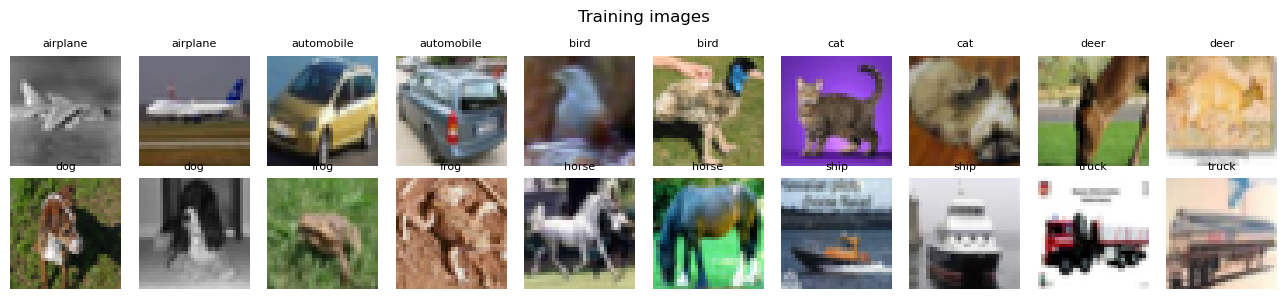

In [6]:
def show_grid(images, titles, cols, path=None, title=None):
    rows = math.ceil(len(images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.3, rows * 1.5), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, img, label in zip(axes.flat, images, titles):
        ax.imshow(img)
        ax.set_title(label, fontsize=8)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()


# Two training images per class.
idx = np.concatenate([np.flatnonzero(y_train == c)[:2] for c in range(10)])
show_grid(x_train[idx], [CLASS_NAMES[y] for y in y_train[idx]], cols=10,
          path=FIG_DIR / 'train_samples.png', title='Training images')

## 3. Augmentation and data loaders
Training images get: random 32×32 crop from a 4-pixel reflect-padded image, horizontal flip,
TrivialAugment (one random photometric or geometric operation per image), and Cutout (a 16×16 square zeroed after normalisation).
When `CUTMIX_PROB > 0`, CutMix is applied to whole batches during training (Section 5); the CutMix experiment turns Cutout off.
Validation (and, in Section 7, test) images are only normalised, using statistics from the training split.
On macOS the augmentation runs in the notebook's own process (no worker processes), and the cell prints how many images per second the CPU can prepare.

In [7]:
class Cutout:
    # Cutout (DeVries & Taylor, 2017): zero one random size x size square of a normalised CHW image.
    def __init__(self, size):
        self.size = size

    def __call__(self, img):
        _, h, w = img.shape
        cy, cx = torch.randint(h, (1,)).item(), torch.randint(w, (1,)).item()
        y0, y1 = max(cy - self.size // 2, 0), min(cy + self.size // 2, h)
        x0, x1 = max(cx - self.size // 2, 0), min(cx + self.size // 2, w)
        img[:, y0:y1, x0:x1] = 0
        return img


class CIFARDataset(Dataset):
    # uint8 NHWC numpy images -> normalised float CHW tensors, with optional training augmentation.
    def __init__(self, images, labels=None, mean=MEAN, std=STD, augment=None, cutout=None):
        self.images = torch.from_numpy(images).permute(0, 3, 1, 2).contiguous()   # (N, 3, 32, 32) uint8
        self.labels = None if labels is None else torch.from_numpy(labels).long()
        self.mean = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)
        self.augment, self.cutout = augment, cutout

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = self.images[i]
        if self.augment is not None:
            img = self.augment(img)                # crop / flip / TrivialAugment on uint8
        img = (img.float() / 255 - self.mean) / self.std
        if self.cutout is not None:
            img = self.cutout(img)
        return img, (self.labels[i] if self.labels is not None else -1)


augment_ops = [T.RandomCrop(32, padding=4, padding_mode='reflect'), T.RandomHorizontalFlip()]
if TRIVIAL_AUGMENT:
    augment_ops.append(T.TrivialAugmentWide())
train_ds = CIFARDataset(x_train, y_train, augment=T.Compose(augment_ops),
                        cutout=Cutout(CUTOUT_SIZE) if CUTOUT_SIZE > 0 else None)
val_ds = CIFARDataset(x_val, y_val)

loader_args = dict(num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda', persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **loader_args)
val_loader = DataLoader(val_ds, batch_size=512, shuffle=False, **loader_args)
print(f'{len(train_loader)} training batches of {BATCH_SIZE} per epoch')

# How fast the CPU produces augmented batches. If this is far below the GPU's training speed, the CPU is the bottleneck.
t0, n = time.time(), 0
for k, (x, _) in enumerate(train_loader):
    n += len(x)
    if k == 19:
        break
print(f'Augmentation + batching on the CPU: {n / (time.time() - t0):,.0f} images per second')

390 training batches of 128 per epoch
Augmentation + batching on the CPU: 6,214 images per second


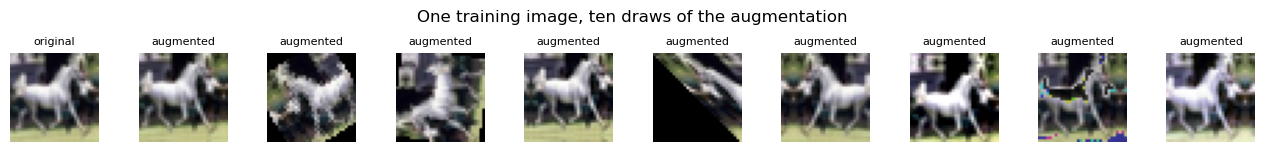

In [8]:
def to_display(img):
    # Undo normalisation for plotting.
    img = img * train_ds.std + train_ds.mean
    return img.clamp(0, 1).permute(1, 2, 0).numpy()


i = int(np.flatnonzero(y_train == 7)[0])    # a horse
show_grid([x_train[i]] + [to_display(train_ds[i][0]) for _ in range(9)], ['original'] + ['augmented'] * 9,
          cols=10, path=FIG_DIR / 'augmentation_examples.png', title='One training image, ten draws of the augmentation')

## 4. Model
Each residual block computes $\mathrm{ReLU}(S(x) + F(x))$, where $F$ = conv3×3 → BN → ReLU → conv3×3 → BN and
$S$ is the identity, or a 1×1 conv + BN when the shape changes.

| Part | Output size | Channels | Content |
|---|---|---|---|
| Stem | 32×32 | 64 | conv 3×3, BN, ReLU |
| Stage 1 | 32×32 | 64 | 4 residual blocks |
| Stage 2 | 16×16 | 128 | 4 residual blocks (first one has stride 2) |
| Stage 3 | 8×8 | 256 | 3 residual blocks (first one has stride 2) |
| Head | 1×1 | 10 | 8×8 average pool (P = 8), linear layer |

Kernel sizes: F_i = 3 for every residual conv, K_i = 1 for the projection shortcuts. Convolutions use Kaiming initialisation.
The last BN of each residual branch starts at zero, so every block starts as an identity mapping (Goyal et al., 2017).

In [9]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                                          nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class ResNet(nn.Module):
    def __init__(self, channels=(64, 128, 256), blocks=(4, 4, 3), num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], kernel_size=3, padding=1, bias=False),
                                  nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        stages, in_ch = [], channels[0]
        for i, (ch, n) in enumerate(zip(channels, blocks)):
            layers = []
            for j in range(n):
                layers.append(BasicBlock(in_ch, ch, stride=2 if (i > 0 and j == 0) else 1))
                in_ch = ch
            stages.append(nn.Sequential(*layers))
        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(in_ch, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, BasicBlock):
                nn.init.zeros_(m.bn2.weight)

    def forward(self, x):
        x = self.stages(self.stem(x))
        return self.fc(self.pool(x).flatten(1))


def build_model():
    model = ResNet(CHANNELS, BLOCKS, num_classes=10).to(DEVICE)
    if DEVICE.type == 'cuda':
        model = model.to(memory_format=torch.channels_last)   # faster convolutions with mixed precision
    return model


def count_trainable(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

In [10]:
model = build_model()
n_params = count_trainable(model)

parts = [('stem', model.stem)]
parts += [(f'stage {i + 1}: {c} ch x {b} blocks', s) for i, (s, c, b) in enumerate(zip(model.stages, CHANNELS, BLOCKS))]
parts += [('classifier (linear)', model.fc)]
for name, module in parts:
    print(f'{name:<30}{count_trainable(module):>12,}')
print(f'{"TOTAL trainable parameters":<30}{n_params:>12,}   (limit {PARAM_LIMIT:,})')
assert n_params <= PARAM_LIMIT, 'Model is over the 5M parameter budget'

model.eval()
with torch.no_grad():
    assert model(torch.zeros(2, 3, 32, 32, device=DEVICE)).shape == (2, 10)

try:   # layer-by-layer table, as suggested in the project description (pip install torchsummary)
    from torchsummary import summary
    summary(model, (3, 32, 32), device=DEVICE.type)
except Exception as e:
    print(f'(torchsummary table skipped: {e})')

stem                                 1,856
stage 1: 64 ch x 4 blocks          295,936
stage 2: 128 ch x 4 blocks       1,116,416
stage 3: 256 ch x 3 blocks       3,280,384
classifier (linear)                  2,570
TOTAL trainable parameters       4,697,162   (limit 5,000,000)
(torchsummary table skipped: No module named 'torchsummary')


## 5. Training
- Loss: cross-entropy with label smoothing 0.1.
- Optional CutMix (`CUTMIX_PROB > 0`): a random box from another image in the batch is pasted in, and the loss mixes the two labels in proportion to the box area.
- Optimiser: SGD with Nesterov momentum 0.9, weight decay 5e-4, batch size 128.
- Learning rate: linear warm-up to 0.1 over 5 epochs, then cosine decay to 0, updated after every batch.
- Mixed precision on the GPU.

After every epoch the model is scored on the validation split. The weights with the best validation accuracy are kept in `<RUN_NAME>_best.pt`, and the full training state in `<RUN_NAME>_last.pt` so the run can resume.

In [11]:
def autocast():
    # Mixed-precision context on GPU, no-op on CPU.
    return torch.autocast(device_type='cuda', dtype=torch.float16) if USE_AMP else contextlib.nullcontext()


def make_grad_scaler():
    if not USE_AMP:
        return None
    try:
        return torch.amp.GradScaler('cuda')
    except (AttributeError, TypeError):    # PyTorch < 2.3
        return torch.cuda.amp.GradScaler()


def load_checkpoint(path):
    try:   # our own file, so full unpickling is safe (PyTorch >= 2.6 defaults to weights_only=True)
        return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:   # PyTorch < 1.13 has no weights_only argument
        return torch.load(path, map_location='cpu')


def warmup_cosine(total_steps, warmup_steps):
    # Learning-rate multiplier per optimizer step: linear warm-up to 1, then cosine decay to 0.
    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))
    return lr_lambda


def to_device(x):
    x = x.to(DEVICE, non_blocking=True)
    return x.contiguous(memory_format=torch.channels_last) if DEVICE.type == 'cuda' else x


def cutmix_batch(x, y):
    # CutMix (Yun et al., 2019): paste a random box from another image of the same batch.
    # Returns the mixed images, the second image's labels, and lam = share of each image that is still its own.
    lam = np.random.beta(CUTMIX_ALPHA, CUTMIX_ALPHA)
    h, w = x.shape[2], x.shape[3]
    cut_h, cut_w = int(h * math.sqrt(1 - lam)), int(w * math.sqrt(1 - lam))
    cy, cx = np.random.randint(h), np.random.randint(w)
    y0, y1 = max(cy - cut_h // 2, 0), min(cy + cut_h // 2, h)
    x0, x1 = max(cx - cut_w // 2, 0), min(cx + cut_w // 2, w)
    perm = torch.randperm(x.size(0)).to(x.device)
    x[:, :, y0:y1, x0:x1] = x[perm, :, y0:y1, x0:x1]
    lam = 1 - (y1 - y0) * (x1 - x0) / (h * w)        # exact share after clipping the box at the border
    return x, y[perm], lam


def train_one_epoch(model, loader, optimizer, scheduler, scaler, criterion):
    model.train()
    loss_sum = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)   # float: CutMix batches count each label by its share
    seen = 0
    for x, y in loader:
        x, y = to_device(x), y.to(DEVICE, non_blocking=True)
        mixed = CUTMIX_PROB > 0 and np.random.rand() < CUTMIX_PROB
        if mixed:
            x, y2, lam = cutmix_batch(x, y)
        with autocast():
            logits = model(x)
            if mixed:
                loss = lam * criterion(logits, y) + (1 - lam) * criterion(logits, y2)
            else:
                loss = criterion(logits, y)
        optimizer.zero_grad(set_to_none=True)
        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        scheduler.step()
        loss_sum += loss.detach() * y.size(0)
        pred = logits.argmax(dim=1)
        if mixed:
            correct += lam * (pred == y).sum() + (1 - lam) * (pred == y2).sum()
        else:
            correct += (pred == y).sum()
        seen += y.size(0)
    return loss_sum.item() / seen, correct.item() / seen


@torch.no_grad()
def predict_probs(model, loader, tta=False):
    # Softmax probabilities for every image in loader, optionally averaged with the mirrored image.
    model.eval()
    chunks = []
    for x, _ in loader:
        x = to_device(x)
        with autocast():
            probs = model(x).float().softmax(dim=1)
            if tta:
                probs = (probs + model(torch.flip(x, dims=[3])).float().softmax(dim=1)) / 2
        chunks.append(probs.cpu())
    return torch.cat(chunks)


def evaluate(model, loader, labels, tta=False):
    # (cross-entropy loss, accuracy, predicted labels) on a labelled loader.
    probs = predict_probs(model, loader, tta)
    labels = torch.as_tensor(labels)
    loss = F.nll_loss(probs.clamp_min(1e-12).log(), labels).item()
    preds = probs.argmax(dim=1)
    return loss, (preds == labels).float().mean().item(), preds.numpy()

In [12]:
seed_everything(SEED)
model = build_model()
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM, nesterov=True, weight_decay=WEIGHT_DECAY)
steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, warmup_cosine(EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch))
scaler = make_grad_scaler()

CKPT_LAST = OUTPUT_DIR / f'{RUN_NAME}_last.pt'
CKPT_BEST = OUTPUT_DIR / f'{RUN_NAME}_best.pt'
HISTORY_PATH = OUTPUT_DIR / f'{RUN_NAME}_history.json'
LOG_PATH = OUTPUT_DIR / f'{RUN_NAME}_log.txt'
RUN_CONFIG = dict(channels=list(CHANNELS), blocks=list(BLOCKS), n_params=count_trainable(model), epochs=EPOCHS,
                  batch_size=BATCH_SIZE, lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY,
                  warmup_epochs=WARMUP_EPOCHS, label_smoothing=LABEL_SMOOTHING, val_size=VAL_SIZE,
                  trivial_augment=TRIVIAL_AUGMENT, cutout_size=CUTOUT_SIZE, cutmix_prob=CUTMIX_PROB,
                  cutmix_alpha=CUTMIX_ALPHA, seed=SEED, n_train=len(train_ds))

history = {k: [] for k in ['epoch', 'lr', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'seconds']}
start_epoch, best_acc, best_epoch = 0, -1.0, 0


def log(message, mode='a'):
    # Print, and append to <RUN_NAME>_log.txt so progress can be followed while the notebook runs headless.
    print(message)
    with open(LOG_PATH, mode) as f:
        f.write(message + '\n')


if RESUME and CKPT_LAST.exists():
    ckpt = load_checkpoint(CKPT_LAST)
    if ckpt['config'] == RUN_CONFIG:
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler'])
        if scaler is not None and ckpt['scaler'] is not None:
            scaler.load_state_dict(ckpt['scaler'])
        start_epoch, history = ckpt['epoch'], ckpt['history']
        best_acc, best_epoch = ckpt['best_acc'], ckpt['best_epoch']
        log(f'Resumed "{RUN_NAME}" after epoch {start_epoch}/{EPOCHS}')
    else:
        print(f'{CKPT_LAST.name} was saved with different settings, so this run starts from scratch')
if start_epoch == 0:
    log(f'run "{RUN_NAME}" | {DEVICE_NAME} | PyTorch {torch.__version__} | {len(train_ds):,} training images | '
        f'{RUN_CONFIG["n_params"]:,} parameters | {EPOCHS} epochs', mode='w')

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    lr_now = optimizer.param_groups[0]['lr']
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, criterion)
    if HAS_VAL:
        val_loss, val_acc, _ = evaluate(model, val_loader, y_val)
    else:
        val_loss, val_acc = float('nan'), float('nan')
    seconds = time.time() - t0

    for key, value in [('epoch', epoch + 1), ('lr', lr_now), ('train_loss', train_loss), ('train_acc', train_acc),
                       ('val_loss', val_loss), ('val_acc', val_acc), ('seconds', seconds)]:
        history[key].append(value)

    # Best = highest validation accuracy. Without a validation split, the latest epoch is kept.
    if not HAS_VAL or val_acc > best_acc:
        best_acc, best_epoch = val_acc, epoch + 1
        torch.save({'model': model.state_dict(), 'epoch': epoch + 1, 'val_acc': val_acc, 'config': RUN_CONFIG},
                   CKPT_BEST)
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict() if scaler is not None else None,
                'epoch': epoch + 1, 'history': history, 'best_acc': best_acc, 'best_epoch': best_epoch,
                'config': RUN_CONFIG}, CKPT_LAST)
    HISTORY_PATH.write_text(json.dumps({'run': RUN_NAME, 'config': RUN_CONFIG, 'history': history}))

    eta_min = np.mean(history['seconds'][-5:]) * (EPOCHS - epoch - 1) / 60
    log(f'epoch {epoch + 1:3d}/{EPOCHS} | lr {lr_now:.4f} | train loss {train_loss:.3f} acc {train_acc:6.2%} | '
          f'val loss {val_loss:.3f} acc {val_acc:6.2%} | {seconds:3.0f}s | ETA {eta_min:5.1f} min')

if HAS_VAL:
    log(f'Done. Best validation accuracy {best_acc:.2%} at epoch {best_epoch}.')
else:
    log('Done. No validation split; the final-epoch weights are used.')
if SMOKE_TEST and history['seconds']:
    full_steps = (len(train_labels) - 5000) // BATCH_SIZE          # a full run trains on 45,000 images per epoch
    sec = history['seconds'][-1] / steps_per_epoch * full_steps
    log(f'Estimated full run on this machine: ~{sec:.0f}s per epoch, i.e. ~{sec * 200 / 3600:.1f} h for 200 epochs, '
        f'~{sec * 120 / 3600:.1f} h for 120, ~{sec * 80 / 3600:.1f} h for 80')

run "cutmix_full" | Apple GPU via MPS (arm64) | PyTorch 2.14.1 | 50,000 training images | 4,697,162 parameters | 200 epochs
epoch   1/200 | lr 0.0001 | train loss 2.182 acc 20.17% | val loss nan acc   nan% | 139s | ETA 459.9 min
epoch   2/200 | lr 0.0201 | train loss 2.075 acc 25.85% | val loss nan acc   nan% | 134s | ETA 450.5 min
epoch   3/200 | lr 0.0401 | train loss 1.968 acc 32.15% | val loss nan acc   nan% | 134s | ETA 445.9 min
epoch   4/200 | lr 0.0601 | train loss 1.857 acc 38.19% | val loss nan acc   nan% | 135s | ETA 443.3 min
epoch   5/200 | lr 0.0801 | train loss 1.799 acc 42.02% | val loss nan acc   nan% | 135s | ETA 440.6 min
epoch   6/200 | lr 0.1000 | train loss 1.752 acc 44.44% | val loss nan acc   nan% | 134s | ETA 435.2 min
epoch   7/200 | lr 0.1000 | train loss 1.685 acc 47.93% | val loss nan acc   nan% | 134s | ETA 432.5 min
epoch   8/200 | lr 0.1000 | train loss 1.627 acc 50.61% | val loss nan acc   nan% | 134s | ETA 429.8 min
epoch   9/200 | lr 0.0999 | train lo

## 6. Results
Training accuracy is measured on augmented images with label smoothing, so it sits below validation accuracy for most of the run. That is expected.

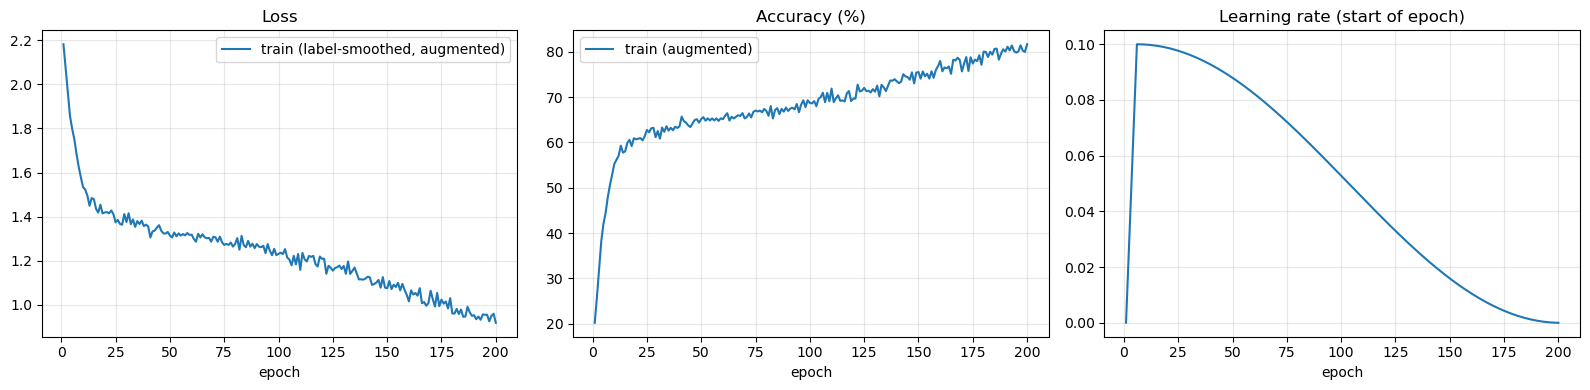

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ep = history['epoch']
axes[0].plot(ep, history['train_loss'], label='train (label-smoothed, augmented)')
axes[1].plot(ep, np.array(history['train_acc']) * 100, label='train (augmented)')
if HAS_VAL:
    axes[0].plot(ep, history['val_loss'], label='validation')
    axes[1].plot(ep, np.array(history['val_acc']) * 100, label='validation')
    axes[1].set_ylim(max(0, min(history['val_acc']) * 100 - 5), 100)
axes[2].plot(ep, history['lr'])
for ax, title in zip(axes, ['Loss', 'Accuracy (%)', 'Learning rate (start of epoch)']):
    ax.set_title(title)
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
axes[0].legend()
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / f'{RUN_NAME}_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
best = load_checkpoint(CKPT_BEST)
model.load_state_dict(best['model'])
n_params = count_trainable(model)

print('=' * 72)
print(f'Model: ResNet, stages {CHANNELS} channels x {BLOCKS} blocks (weights from epoch {best["epoch"]})')
print(f'Number of trainable parameters: {n_params:,} (limit {PARAM_LIMIT:,}) -> '
      f'{"within budget" if n_params <= PARAM_LIMIT else "OVER BUDGET"}')
if HAS_VAL:
    _, acc_plain, preds_plain = evaluate(model, val_loader, y_val)
    _, acc_tta, preds_tta = evaluate(model, val_loader, y_val, tta=True)
    val_preds = preds_tta if TTA_FLIP else preds_plain
    log(f'FINAL held-out accuracy ({len(y_val):,} images never used for training): {acc_plain:.2%}')
    log(f'FINAL held-out accuracy with flip test-time augmentation:          {acc_tta:.2%}')
else:
    print('No validation split in this run (VAL_SIZE = 0): use the Kaggle leaderboard score as the test accuracy.')
print('=' * 72)

Model: ResNet, stages (64, 128, 256) channels x (4, 4, 3) blocks (weights from epoch 200)
Number of trainable parameters: 4,697,162 (limit 5,000,000) -> within budget
No validation split in this run (VAL_SIZE = 0): use the Kaggle leaderboard score as the test accuracy.


In [15]:
if HAS_VAL:
    cm = np.zeros((10, 10), dtype=int)
    np.add.at(cm, (y_val, val_preds), 1)
    per_class = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.25, 1]})
    axes[0].imshow(cm, cmap='Blues')
    axes[0].set_xticks(range(10), CLASS_NAMES, rotation=45, ha='right')
    axes[0].set_yticks(range(10), CLASS_NAMES)
    axes[0].set_xlabel('predicted')
    axes[0].set_ylabel('true')
    axes[0].set_title('Validation confusion matrix')
    for r in range(10):
        for c in range(10):
            axes[0].text(c, r, cm[r, c], ha='center', va='center', fontsize=8,
                         color='white' if cm[r, c] > cm.max() / 2 else 'black')
    axes[1].barh(CLASS_NAMES, per_class * 100)
    axes[1].invert_yaxis()
    axes[1].set_xlim(max(0, per_class.min() * 100 - 5), 100)
    axes[1].set_title('Validation accuracy per class (%)')
    for k, v in enumerate(per_class):
        axes[1].text(v * 100, k, f' {v:.1%}', va='center', fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{RUN_NAME}_confusion_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()

## 7. Kaggle submission
The hidden test images are loaded here for the first time, after training and model selection are finished.
They only pass through the final model to produce predictions. They are not used for training, validation, normalisation statistics or any choice of model or settings.

Predictions are matched to `sample_submission.csv` by id, so the file keeps its exact column names and row order.
The saved file is then read back and checked against the format rules. Each team may submit at most **5 times per day**.

Test images: (2000, 32, 32, 3) from data/test_images/; first ids [0, 1, 2]
Sample submission: data/sample_submission.csv


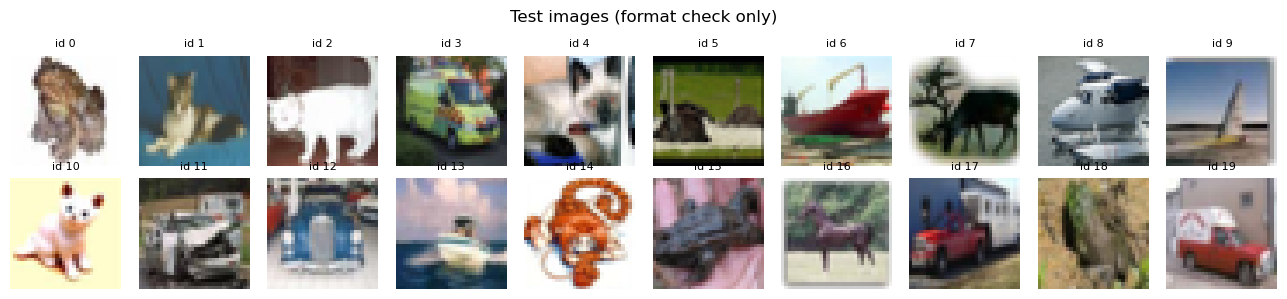

In [16]:
test_images, test_ids = load_test_data(DATA_DIR)
sample_path = DATA_DIR / 'sample_submission.csv'
print(f'Test images: {test_images.shape} from {DATA_DIR / "test_images"}/; first ids {test_ids[:3]}')
print(f'Sample submission: {sample_path}')

# Visual check that the images were decoded correctly (colours and orientation should look natural).
show_grid(test_images[:20], [f'id {i}' for i in test_ids[:20]], cols=10, title='Test images (format check only)')

In [17]:
def build_submission(test_ids, predictions, sample_path=None):
    # One integer prediction per test id, in the column names and row order of sample_submission.csv.
    predictions = [int(p) for p in predictions]
    if len(predictions) != len(test_ids):
        raise ValueError(f'{len(predictions)} predictions for {len(test_ids)} test ids')

    def key(i):
        return str(i).strip()

    pred_by_id = {key(i): p for i, p in zip(test_ids, predictions)}
    if len(pred_by_id) != len(predictions):
        raise ValueError('test ids are not unique')
    if sample_path is None:
        print('No sample_submission.csv found: writing columns id,label in test-file order')
        return pd.DataFrame({'id': list(test_ids), 'label': predictions})

    sample = pd.read_csv(sample_path)
    if sample.shape[1] != 2:
        raise ValueError(f'sample submission has {sample.shape[1]} columns {list(sample.columns)}; expected 2')
    id_col, label_col = sample.columns
    if [id_col, label_col] != ['id', 'label']:
        print(f'NOTE: the rules say columns id,label but the sample uses {id_col},{label_col}; following the sample')
    missing = [i for i in sample[id_col] if key(i) not in pred_by_id]
    if missing:
        raise ValueError(f'{len(missing)} ids in the sample submission have no prediction, e.g. {missing[:5]}')
    if len(pred_by_id) != len(sample):
        raise ValueError(f'{len(pred_by_id)} test images but {len(sample)} rows in the sample submission')
    return pd.DataFrame({id_col: sample[id_col], label_col: [pred_by_id[key(i)] for i in sample[id_col]]})


def verify_submission_file(path, sample_path, n_test):
    # Read the saved CSV back and check it against the competition's format rules.
    sub = pd.read_csv(path)
    problems = []
    expected = list(pd.read_csv(sample_path, nrows=0).columns) if sample_path is not None else ['id', 'label']
    if list(sub.columns) != expected:
        problems.append(f'columns {list(sub.columns)} != {expected}')
    if sub.shape[1] != 2:
        problems.append(f'{sub.shape[1]} columns instead of exactly 2')
    if sub.isna().any().any():
        problems.append('missing values')
    labels = sub.iloc[:, 1]
    if labels.dtype.kind != 'i' or not labels.between(0, 9).all():
        problems.append('labels are not integers 0-9')
    if not sub.iloc[:, 0].is_unique:
        problems.append('duplicate ids')
    if len(sub) != n_test:
        problems.append(f'{len(sub)} rows for {n_test} test images')
    if sample_path is not None:
        sample_ids = pd.read_csv(sample_path).iloc[:, 0].astype(str)
        if not sub.iloc[:, 0].astype(str).equals(sample_ids):
            problems.append('ids or their order differ from the sample submission')
    if problems:
        raise ValueError(f'{path.name} breaks the submission rules: ' + '; '.join(problems))
    print(f'{path.name}: format OK ({len(sub):,} rows, columns {list(sub.columns)}, labels 0-9, sample order)')

In [18]:
test_loader = DataLoader(CIFARDataset(test_images, mean=MEAN, std=STD), batch_size=512, shuffle=False, **loader_args)
test_preds = predict_probs(model, test_loader, tta=TTA_FLIP).argmax(dim=1).numpy()   # best checkpoint from Section 6
submission = build_submission(test_ids, test_preds, sample_path)

# submission.csv is the file to upload; <RUN_NAME>_submission.csv keeps a copy per run.
# The smoke test writes only smoke_submission.csv, which must not be uploaded.
out_files = ([OUTPUT_DIR / 'smoke_submission.csv'] if SMOKE_TEST
             else [OUTPUT_DIR / 'submission.csv', OUTPUT_DIR / f'{RUN_NAME}_submission.csv'])
for path in out_files:
    submission.to_csv(path, index=False)
    verify_submission_file(path, sample_path, len(test_ids))
log(f'Submission written and format-checked: {out_files[0]} ({len(submission):,} rows)')
print(submission.head().to_string(index=False))

submission.csv: format OK (2,000 rows, columns ['id', 'label'], labels 0-9, sample order)
cutmix_full_submission.csv: format OK (2,000 rows, columns ['id', 'label'], labels 0-9, sample order)
Submission written and format-checked: outputs/submission.csv (2,000 rows)
 id  label
  0      6
  1      3
  2      3
  3      9
  4      3


## 8. Comparing runs (for the report)
Every run saves `<RUN_NAME>_history.json`. Train variants with different `RUN_NAME`s (for example other `BLOCKS`/`CHANNELS`,
or without TrivialAugment or Cutout), then run this cell to compare them in one table and one plot.

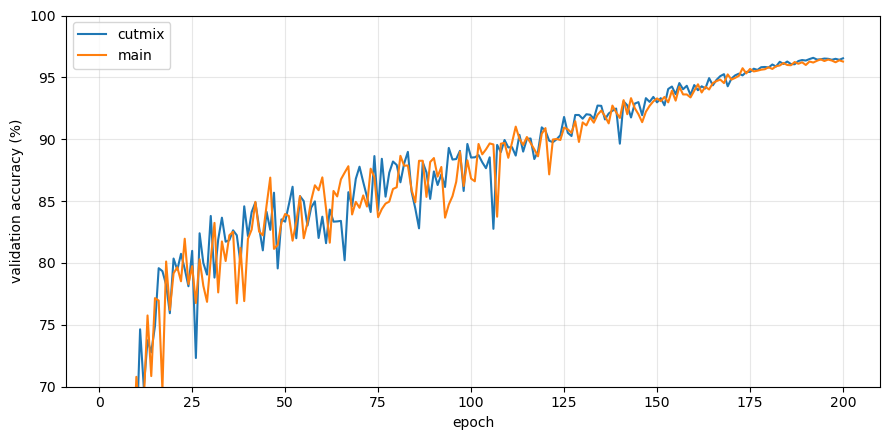

        run       channels    blocks    params  epochs  TrivialAugment  cutout  CutMix best val acc
cutmix_full [64, 128, 256] [4, 4, 3] 4,697,162 200/200            True       0     0.5         nan%
     cutmix [64, 128, 256] [4, 4, 3] 4,697,162 200/200            True       0     0.5       96.58%
       full [64, 128, 256] [4, 4, 3] 4,697,162 200/200            True      16     0.0         nan%
       main [64, 128, 256] [4, 4, 3] 4,697,162 200/200            True      16     0.0       96.46%


In [19]:
rows, best_vals = [], []
fig, ax = plt.subplots(figsize=(9, 4.5))
for path in sorted(OUTPUT_DIR.glob('*_history.json')):
    rec = json.loads(path.read_text())
    if rec['run'] == 'smoke' and not SMOKE_TEST:
        continue
    cfg, h = rec['config'], rec['history']
    val = np.array(h['val_acc'], dtype=float)
    best_val = np.nanmax(val) if np.isfinite(val).any() else float('nan')
    rows.append({'run': rec['run'], 'channels': cfg['channels'], 'blocks': cfg['blocks'], 'params': f"{cfg['n_params']:,}",
                 'epochs': f"{len(h['epoch'])}/{cfg['epochs']}", 'TrivialAugment': cfg['trivial_augment'],
                 'cutout': cfg['cutout_size'], 'CutMix': cfg.get('cutmix_prob', 0.0), 'best val acc': f'{best_val:.2%}'})
    if np.isfinite(val).any():
        ax.plot(h['epoch'], val * 100, label=rec['run'])
        best_vals.append(best_val)
ax.set_xlabel('epoch')
ax.set_ylabel('validation accuracy (%)')
if best_vals and min(best_vals) > 0.8:
    ax.set_ylim(70, 100)
ax.grid(alpha=0.3)
if rows:
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'run_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(pd.DataFrame(rows).to_string(index=False))

## Results log
Recorded after the competition closed. Validation accuracies come from the outputs of the 45,000-image runs (Section 6);
Kaggle scores were copied from the leaderboard, since the test labels are hidden and test accuracy exists only on Kaggle.
Every model has **4,697,162** trainable parameters.

| Run | Notebook | Training images | Regulariser | Validation (single view / mirror-averaged) | Kaggle public | Kaggle private |
|---|---|---|---|---|---|---|
| main | `resnet_cifar10_training_main_run.ipynb` | 45,000 | Cutout | 96.46% / 96.60% | 0.880 | not recorded |
| full (**final submission**) | `resnet_cifar10_training_full_run.ipynb` | 50,000 | Cutout | no validation split | **0.889** | 0.864 |
| cutmix | `resnet_cifar10_cutmix.ipynb` | 45,000 | CutMix | 96.58% / 96.60% | not submitted | not submitted |
| cutmix_full (**final submission**) | `resnet_cifar10_cutmix_full.ipynb` | 50,000 | CutMix | no validation split | 0.888 | **0.866** |

Both full-data models were selected as final submissions. Kaggle ranks by the better private score, so the final
private score is **0.866** (cutmix_full); the highest public score, 0.889, came from the Cutout model (full).
The cell below prints this notebook's run. It is print-only and needs no training state, so it can be run on its own.

In [ ]:
# Results log: recorded values, entered after the competition closed (print-only; needs no training state).
RUN = 'cutmix_full'   # this notebook's run

N_PARAMS, PARAM_LIMIT = 4_697_162, 5_000_000
RESULTS = {  # run: training images, regulariser, validation accuracy, Kaggle public, Kaggle private
    'main':        ('45,000', 'Cutout', '96.46% single view, 96.60% mirror-averaged', '88.00%', 'not recorded'),
    'full':        ('50,000', 'Cutout', 'no validation split (all 50,000 images used)', '88.90%', '86.40%'),
    'cutmix':      ('45,000', 'CutMix', '96.58% single view, 96.60% mirror-averaged', 'not submitted', 'not submitted'),
    'cutmix_full': ('50,000', 'CutMix', 'no validation split (all 50,000 images used)', '88.80%', '86.60%'),
}
FINAL_SUBMISSIONS = ('full', 'cutmix_full')   # both selected on Kaggle; the private leaderboard uses the better one

images, reg, val, public, private = RESULTS[RUN]
print('=' * 72)
print(f'Run "{RUN}": {images} training images, {reg}')
print(f'Trainable parameters:           {N_PARAMS:,} (limit {PARAM_LIMIT:,})')
print(f'Held-out validation accuracy:   {val}')
print(f'Kaggle public leaderboard:      {public}')
print(f'Kaggle private leaderboard:     {private}')
if RUN in FINAL_SUBMISSIONS:
    print('Selected as a final submission. Final private score (better of the two final submissions): 86.60%')
print('=' * 72)

Run "cutmix_full": 50,000 training images, CutMix
Trainable parameters:           4,697,162 (limit 5,000,000)
Held-out validation accuracy:   no validation split (all 50,000 images used)
Kaggle public leaderboard:      88.80%
Kaggle private leaderboard:     86.60%
Selected as a final submission. Final private score (better of the two final submissions): 86.60%


## References
- K. He, X. Zhang, S. Ren, J. Sun. *Deep Residual Learning for Image Recognition.* CVPR 2016.
- K. Liu. *pytorch-cifar*, https://github.com/kuangliu/pytorch-cifar. The basic-block structure follows this repository.
- T. DeVries, G. W. Taylor. *Improved Regularization of Convolutional Neural Networks with Cutout.* arXiv:1708.04552, 2017.
- S. Yun, D. Han, S. J. Oh, S. Chun, J. Choe, Y. Yoo. *CutMix: Regularization Strategy to Train Strong Classifiers with Localizable Features.* ICCV 2019.
- S. G. Müller, F. Hutter. *TrivialAugment: Tuning-free Yet State-of-the-Art Data Augmentation.* ICCV 2021.
- C. Szegedy, V. Vanhoucke, S. Ioffe, J. Shlens, Z. Wojna. *Rethinking the Inception Architecture for Computer Vision* (label smoothing). CVPR 2016.
- I. Loshchilov, F. Hutter. *SGDR: Stochastic Gradient Descent with Warm Restarts* (cosine schedule). ICLR 2017.
- P. Goyal et al. *Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour* (warm-up, zero-initialised residual BN). arXiv:1706.02677, 2017.
- A. Paszke et al. *PyTorch: An Imperative Style, High-Performance Deep Learning Library.* NeurIPS 2019. TrivialAugment, random crop and flip come from torchvision.